# Exercise 03: Advanced Text Processing

> **Chapter:** Ch03 - Advanced Text Processing
> **Estimated time:** ~65 minutes
>
> This exercise is optional. No submission, no grading.
> The solution notebook is released one week after the exercise.

A search or support system routes a user's words to the right backend. To do that it first turns
raw text into useful features, and every step of that pipeline is a choice. This exercise puts you
in a realistic position: you are standing up a new customer-support bot and you have only a handful
of labelled example utterances per intent. Your job is to build an intent classifier and push its
accuracy as high as you can. The classifier is a Naive Bayes model from the chapter. The interesting
part is not the model. It is the text processing you feed it: how you tokenize, what you normalize,
what you throw away. You will discover which choices earn their keep when data is scarce, and which
ones do not. Then you will face the question every team asks today: an LLM would probably close the
last of the gap, so should you just use one? You will measure the answer, not guess it. Three short
reasoning tasks frame the build: one on the Naive Bayes prior, one on your own results, one on the
LLM trade-off.

**Your tasks** (tick them off as you go):

- [ ] **Quiz** - 20 questions in the quiz app
- [ ] ✏ **T1: When the prior takes over** - diagnose a Naive Bayes router stuck on one backend
- [ ] 💻 **C1: A few-shot intent classifier** - build and tune the classifier in `tasks.py`
- [ ] ✏ **T2: Why less is sometimes more** - explain what helped, what did not, and why
- [ ] ✏ **T3: Should you reach for an LLM?** - weigh quality against cost and latency

---

## Quiz

Open the quiz app and work through the **20 questions** for this chapter. On the start screen,
pick the topic **"03 - Advanced Text Processing"**:

**Quiz app:** https://roger-weber.github.io/mmir-unibasel-hs26/quiz/

The quiz covers definitions and basic concepts. The tasks below go further: they ask you to diagnose
a broken classifier, build a working one, and explain your own results.

---

## When the prior takes over

> **How this works:** Write your answer in the markdown cell below the question (replace
> *Your answer here...*). The solution notebook fills the same cell with a model answer, so you can
> compare and reflect.

The chapter routes a query to a backend with a Naive Bayes classifier, using the log-form decision
rule $\hat{C} = \arg\max_k \left( \log P(C_k) + \sum_j \log P(x_j \mid C_k) \right)$. You will build
exactly this model below. First, reason about a way it can fail.

### ✏ Task T1 - When the prior takes over

You train an intent router on a year of query logs, labelled with the backend each user clicked. In
those logs, 80% of queries went to `web_search`, and the remaining 20% were spread over
`people_search`, `book_search`, `map_search`, and a few more. You estimate the prior $P(C_k)$ directly
from these fractions. In production the router sends almost every query to `web_search`. Even a clear
query like "Who is Ada Lovelace?", which carries a WH-word and a PERSON entity and should go to
`people_search`, is routed to `web_search`.

1. Work through the decision rule for that query. Why do the two strong `people_search` features fail
   to change the outcome?
2. Would a query with many more features behave the same way? Explain.
3. Propose a concrete fix and name what it costs. Under what conditions would keeping the empirical
   prior be the right choice instead?

**1. The prior term dominates the short sum.** The decision rule adds one prior term
$\log P(C_k)$ and one likelihood term per feature. With an empirical prior,
$\log P(\text{web\_search}) = \log 0.8 \approx -0.22$, while a minority class like
$\log P(\text{people\_search}) = \log 0.03 \approx -3.5$. So `web_search` starts more than 3 units
ahead before any feature is read. "Who is Ada Lovelace?" contributes only a few feature terms. Each
term nudges the two classes by a modest amount. The gap those few terms can close is smaller than the
head start the prior handed to `web_search`, so `web_search` still wins the argmax. The prior term,
estimated from an imbalanced log, is responsible. It encodes the past traffic mix rather than the
meaning of this query.

**2. More features dilute the prior.** The prior contributes a single fixed term to each class score.
The likelihood contributes one term per feature, and those terms accumulate. A long query with many
strong `people_search` features adds many favourable terms to that class, and their sum can overcome
the constant prior gap. A short query adds only a few terms, so the fixed prior gap stays large
relative to the evidence. The effect bites hardest on short queries, which are also the most common.

**3. Fix and cost.** Balance the training data across intents, or set a uniform prior
$P(C_k) = 1/K$ so the prior term is the same constant for every class and drops out of the argmax.
Then the features alone decide. The cost is that you discard real information about base rates. If
`web_search` genuinely is the right answer for most ambiguous queries, a uniform prior will now
over-route those to niche backends and hurt the common case. Keeping the empirical prior is right
when the training distribution matches the real world. The problem here is not that priors exist, but
that this prior was estimated from traffic skewed by the old system's own routing. The principled fix
is to correct the training distribution, and to fall back to uniform priors only when you cannot.

---

## The customer-support dataset

You will work with the **Bitext customer-support dataset**: about 27,000 real user utterances, each
labelled with one of **27 intents** such as `track_order`, `get_refund`, `recover_password`, or
`cancel_order`. The intents are grouped into 11 coarse categories, but you classify the fine intent.

The realistic constraint is **scarce labels**. A new bot does not start with thousands of labelled
examples per intent. The loader below gives you a **few-shot** training set of just **10 utterances
per intent** (270 in total), plus a large validation set to tune on and a held-out test set for the
final score. The split is fixed by a hash of each utterance, so everyone trains and tests on exactly
the same data. Tune your choices on the validation set. Report the final number on the test set only.

Run the cell below first. On first use it downloads the dataset from Kaggle (a few MB, cached
afterwards) and the NLTK resources your pipeline may need.

In [1]:
# Standard setup - run this first
import sys, pathlib

# Make `shared/` importable regardless of notebook depth
# (exercise notebooks live in exercises/chNN/, solutions in exercises/chNN/solution/).
_p = pathlib.Path().resolve()
while not (_p / "shared").is_dir() and _p != _p.parent:
    _p = _p.parent
sys.path.insert(0, str(_p))

%load_ext autoreload
%autoreload 2

import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from shared.support_intents import load_support_intents
from shared.display import print_table, display_md

data = load_support_intents(shots=10, label="intent")
display_md(
    f"**Training utterances:** {len(data.train)} ({len(data.labels)} intents, "
    f"10 each)  |  **Validation:** {len(data.val)}  |  **Test:** {len(data.test)}\n\n"
    f"**Example (utterance -> intent):**\n\n"
    + "\n".join(f"- `{t}`  ->  **{y}**" for t, y in data.train[:4])
)

**Training utterances:** 270 (27 intents, 10 each)  |  **Validation:** 3947  |  **Test:** 4047

**Example (utterance -> intent):**

- `is it possible to check when will my parcel arrive?`  ->  **delivery_period**
- `I have to see how soon can I expect the delivery, help me`  ->  **delivery_period**
- `I would like to check how soon can I expect the shipment`  ->  **delivery_period**
- `want help to chck how soon can i expect my order`  ->  **delivery_period**

## Building a few-shot intent classifier

> **How this works:** Implement the class described below in `tasks.py`. You can write the code
> yourself or direct an AI to implement it from the spec. After saving `tasks.py`, re-run the verify
> cell; autoreload picks up your changes, no kernel restart needed.

### 💻 Task C1 - A few-shot intent classifier

Implement `IntentClassifier` in `tasks.py`. It is a multinomial Naive Bayes model over bag-of-words
features, with the feature pipeline under your control. Three methods do the work:

- `extract_features(self, text) -> list[str]` - turn one utterance into a list of feature tokens.
  Start by lowercasing and splitting into word tokens. Then apply the steps the constructor flags
  request: `remove_stopwords`, `stemming`, `lemmatization`. This method is where the exercise really
  happens: the model is fixed, but the features you produce decide how well it works.
- `train(self, data) -> self` - `data` is a list of `(utterance, label)` pairs. Count, per class, how
  many documents it has and how often each feature token occurs in it. Also record the vocabulary
  size, so you can smooth.
- `predict(self, text) -> str` - return the most probable class. Score each class in log space:
  the prior term plus, for every feature token, $\log P(t \mid C)$ with **add-one (Laplace)
  smoothing**, $P(t \mid C) = \dfrac{\text{count}(t, C) + 1}{\text{total tokens in } C + |V|}$. The
  prior term is $\log P(C)$ for `prior="observed"` and a constant (drop it) for `prior="uniform"`.

The constructor takes `remove_stopwords=False, stemming=False, lemmatization=False, prior="uniform"`,
so you can switch pipelines without rewriting the class. Correct behaviour: an untuned bag-of-words
classifier must already beat the 1-in-27 random baseline by a wide margin, and your text pipeline
must lift it further. On this balanced training set the two priors must give the same predictions.

The two helpers below are provided. `accuracy` is the single number you optimize. `top_confusions`
lists the intent pairs the classifier mixes up most, so you can see *where* it fails, not just how
often.

In [2]:
# --- Provided: evaluation helpers (you do not implement these) ---
from collections import Counter

def accuracy(clf, dataset) -> float:
    """Fraction of utterances whose predicted label matches the true label."""
    return sum(clf.predict(text) == label for text, label in dataset) / len(dataset)

def top_confusions(clf, dataset, k=8):
    """The k most frequent (true label -> predicted label) mistakes."""
    confused = Counter()
    for text, label in dataset:
        predicted = clf.predict(text)
        if predicted != label:
            confused[(label, predicted)] += 1
    return confused.most_common(k)

In [3]:
# --- Verify C1 ---
from tasks import IntentClassifier

# A plain bag-of-words classifier already beats the 1-in-27 random baseline by a wide margin.
baseline = IntentClassifier().train(data.train)
baseline_acc = accuracy(baseline, data.test)
assert baseline_acc >= 0.65, f"baseline test accuracy too low: {baseline_acc:.3f} (random is ~0.04)"

# Stop-word removal plus stemming should lift accuracy well above the plain baseline.
tuned = IntentClassifier(remove_stopwords=True, stemming=True).train(data.train)
tuned_acc = accuracy(tuned, data.test)
assert tuned_acc >= 0.78, f"tuned test accuracy too low: {tuned_acc:.3f}"
assert tuned_acc > baseline_acc, "normalization should help when training data is scarce"

# On this balanced training set the prior carries no information: uniform and observed agree.
observed = IntentClassifier(remove_stopwords=True, stemming=True, prior="observed").train(data.train)
assert abs(accuracy(observed, data.test) - tuned_acc) < 0.01, "uniform and observed prior should match here"

print(f"✓ baseline {baseline_acc:.3f} -> tuned {tuned_acc:.3f} on the held-out test set!")

✓ baseline 0.726 -> tuned 0.817 on the held-out test set!


In [4]:
# --- Explore C1 ---
# Which choices actually earn their keep? Tune on the VALIDATION set, never the test set.
configs = [
    ("baseline (bag of words)", dict()),
    ("+ stop-words", dict(remove_stopwords=True)),
    ("+ stop-words + stemming", dict(remove_stopwords=True, stemming=True)),
    ("+ stop-words + lemmatization", dict(remove_stopwords=True, lemmatization=True)),
]
display_md("**Pipeline comparison (validation accuracy):**")
print_table(
    [[name, f"{accuracy(IntentClassifier(**kw).train(data.train), data.val):.3f}"]
     for name, kw in configs],
    headers=["Pipeline", "Validation accuracy"],
)

# Pick the winner on validation, then report it once on the held-out test set.
best = IntentClassifier(remove_stopwords=True, stemming=True).train(data.train)
display_md(f"**Chosen pipeline, held-out test accuracy:** {accuracy(best, data.test):.3f}")

# Where does it still fail? These are the intents whose utterances share the most vocabulary.
display_md("**Most common confusions:**")
print_table(
    [[f"{true} -> {pred}", count] for (true, pred), count in top_confusions(best, data.test)],
    headers=["Confused (true -> predicted)", "Count"],
)

**Pipeline comparison (validation accuracy):**

| Pipeline                     |   Validation accuracy |
|:-----------------------------|----------------------:|
| baseline (bag of words)      |                 0.719 |
| + stop-words                 |                 0.753 |
| + stop-words + stemming      |                 0.817 |
| + stop-words + lemmatization |                 0.809 |

**Chosen pipeline, held-out test accuracy:** 0.817

**Most common confusions:**

| Confused (true -> predicted)                       |   Count |
|:---------------------------------------------------|--------:|
| delivery_options -> check_payment_methods          |      43 |
| delivery_options -> delivery_period                |      40 |
| registration_problems -> payment_issue             |      27 |
| track_refund -> check_refund_policy                |      26 |
| change_shipping_address -> set_up_shipping_address |      24 |
| get_refund -> check_refund_policy                  |      21 |
| delete_account -> switch_account                   |      19 |
| set_up_shipping_address -> change_shipping_address |      19 |

### ✏ Task T2 - Why less is sometimes more

You trained on only 10 utterances per intent. Your experiments showed two things:

- Stop-word removal plus stemming raised test accuracy well above the plain bag-of-words baseline.
- Switching the prior from uniform to observed changed nothing.

1. Explain why stemming and stop-word removal help so much when training data is this scarce. Then
   predict what happens to the size of that improvement as you collect more labelled utterances per
   intent, and justify your prediction.
2. Your classifier scored the same with a uniform prior and an observed prior. Reconcile this with
   Task T1, where the prior decided the outcome. What is different here?

**1. Normalization fights sparsity.** With only 10 utterances per intent, most words are seen once or
not at all for a given intent. A test utterance that says "tracking" gains nothing from a training
utterance that said "track", because to a bag-of-words model they are different tokens. Stemming maps
"track", "tracking", and "tracked" to one token, so a single training example now covers all three
surface forms. This multiplies the effective evidence per word, which matters most exactly when
evidence is scarce. Stop-word removal helps for the opposite reason. Function words like "the", "to",
"a" occur in every intent, so they add smoothed likelihood terms that are almost equal across classes.
They do not discriminate, and with so few real content words per utterance they dilute the signal.
Removing them concentrates the score on the words that separate intents.

The improvement should **shrink as data grows**. With many examples per intent, the model eventually
sees "track", "tracking", and "tracked" as separate tokens often enough to learn each one, so
collapsing them adds little. The gain is largest in the scarce regime and tapers off. A student who
reruns with more shots per intent will see the baseline climb toward the tuned pipeline, and the gap
between them narrow.

**2. Here the features decide, not the prior.** Two things differ from Task T1. First, the training
set is **balanced**: exactly 10 utterances per intent, so every $P(C_k)$ is equal and the prior term
is the same constant for all classes. It drops out of the argmax whether you call it uniform or
observed, so the two settings are identical. Second, the features are **strong and plentiful**
relative to the number of classes. A support utterance names its intent with content words like
"refund" or "password", so the likelihood sum is decisive and would dominate even a mild prior
imbalance. Task T1 was the mirror image: an imbalanced prior and a short query with weak features, so
the prior won. The prior matters only when the training distribution is skewed and the per-query
evidence is too thin to overcome it. Neither condition holds here.

---

## Checking the prediction: a learning curve

Task T2 asked you to predict what more training data would do. Now see it. The cell below reruns your
classifier for a range of training-set sizes, from 5 up to 100 labelled utterances per intent, and
plots the plain baseline against your tuned pipeline on the same held-out test set. Watch both curves
and the distance between them.

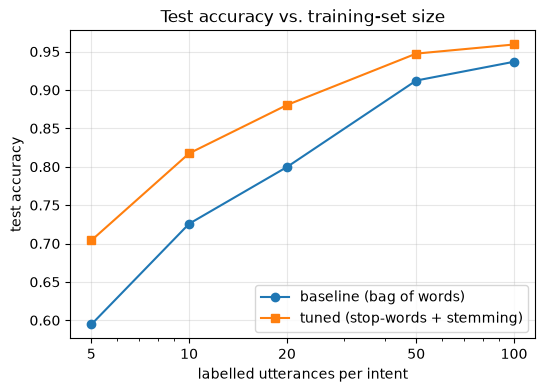

In [5]:
# --- Provided: learning curve (uses your IntentClassifier) ---
import matplotlib.pyplot as plt

shots_grid = [5, 10, 20, 50, 100]
baseline_curve, tuned_curve = [], []
for k in shots_grid:
    d = load_support_intents(shots=k, label="intent")
    baseline_curve.append(accuracy(IntentClassifier().train(d.train), d.test))
    tuned_curve.append(accuracy(
        IntentClassifier(remove_stopwords=True, stemming=True).train(d.train), d.test))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(shots_grid, baseline_curve, "o-", label="baseline (bag of words)")
ax.plot(shots_grid, tuned_curve, "s-", label="tuned (stop-words + stemming)")
ax.set_xscale("log")
ax.set_xticks(shots_grid)
ax.set_xticklabels(shots_grid)
ax.set_xlabel("labelled utterances per intent")
ax.set_ylabel("test accuracy")
ax.set_title("Test accuracy vs. training-set size")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

More labelled data helps, but labels are expensive to collect. There is another way to chase the
remaining accuracy that needs no new labels at all: hand each utterance to a large language model and
ask it for the intent. It is the first thing many teams reach for. Before you do, measure what it
actually costs.

---

## Should you reach for an LLM?

An LLM can classify an utterance zero-shot: give it the list of intents and the message, and it
replies with a label. No training, no feature engineering. It usually scores higher than a small
Naive Bayes model. The cell below compares the two on the same task. The LLM figures were measured on
a 200-utterance sample with Claude Haiku 4.5, a small and fast model. Running an LLM over the full
4,000-utterance test set would take about an hour and cost real money, which is already part of the
story. Your Naive Bayes classifier scores about 0.82 on that same sample, so the comparison is fair.

In [6]:
# --- Provided: Naive Bayes vs. LLM ---
import time

clf = IntentClassifier(remove_stopwords=True, stemming=True).train(data.train)
nb_acc = accuracy(clf, data.test)
t0 = time.time()
for text, _ in data.test[:500]:
    clf.predict(text)
nb_latency_ms = (time.time() - t0) / 500 * 1000

# LLM numbers measured on a 200-utterance sample with Claude Haiku 4.5 (see note above).
LLM_ACCURACY, LLM_LATENCY_MS = 0.89, 941
LLM_TOKENS_IN, LLM_TOKENS_OUT = 177, 7          # per query; most input is the 27-intent instruction
PRICE_IN, PRICE_OUT = 1.00, 5.00                # US$ per million tokens, Claude Haiku 4.5 list price

llm_cost_1k = (LLM_TOKENS_IN * PRICE_IN + LLM_TOKENS_OUT * PRICE_OUT) / 1e6 * 1000
# Prompt caching: the ~150-token intent list repeats on every call and can be re-read at ~0.1x.
cached_in = 150 * 0.1 + (LLM_TOKENS_IN - 150)
llm_cost_1k_cached = (cached_in * PRICE_IN + LLM_TOKENS_OUT * PRICE_OUT) / 1e6 * 1000

print_table(
    [["Naive Bayes (tuned)", f"{nb_acc:.3f}", f"{nb_latency_ms:.2f} ms", "~$0"],
     ["LLM (Haiku 4.5)", f"{LLM_ACCURACY:.3f}", f"{LLM_LATENCY_MS} ms", f"${llm_cost_1k:.2f}"],
     ["LLM + prompt caching", f"{LLM_ACCURACY:.3f}", f"{LLM_LATENCY_MS} ms", f"${llm_cost_1k_cached:.2f}"]],
    headers=["Method", "Test accuracy", "Latency / query", "Cost / 1000 queries"],
)

Q = 1_000_000
display_md(
    f"**Serving {Q:,} queries on one thread:**\n\n"
    f"- Naive Bayes: about {nb_latency_ms * Q / 1000 / 60:.0f} min, about $0.\n"
    f"- LLM: about {LLM_LATENCY_MS * Q / 1000 / 3600 / 24:.0f} days, about "
    f"${llm_cost_1k * Q / 1000:,.0f} (${llm_cost_1k_cached * Q / 1000:,.0f} with caching).\n\n"
    f"The LLM buys roughly +{(LLM_ACCURACY - nb_acc) * 100:.0f} points of accuracy, at about "
    f"{LLM_LATENCY_MS / nb_latency_ms:,.0f}x the latency per query and a bill that grows with traffic."
)

| Method               |   Test accuracy | Latency / query   | Cost / 1000 queries   |
|:---------------------|----------------:|:------------------|:----------------------|
| Naive Bayes (tuned)  |           0.817 | 0.07 ms           | ~$0                   |
| LLM (Haiku 4.5)      |           0.89  | 941 ms            | $0.21                 |
| LLM + prompt caching |           0.89  | 941 ms            | $0.08                 |

**Serving 1,000,000 queries on one thread:**

- Naive Bayes: about 1 min, about $0.
- LLM: about 11 days, about $212 ($77 with caching).

The LLM buys roughly +7 points of accuracy, at about 14,280x the latency per query and a bill that grows with traffic.

In [7]:
# --- Optional: run the LLM yourself (needs AWS Bedrock access) ---
# Classifies a few utterances with a real LLM call so you can see a prediction and its latency.
# Optional: with no credentials this cell prints a note and the rest of the exercise still works.
try:
    from shared.llm import invoke_claude
    LLM_MODEL = "global.anthropic.claude-haiku-4-5-20251001-v1:0"
    system = ("You are an intent classifier for a customer-support bot. Classify the user's message "
              "into exactly ONE of these intents:\n" + ", ".join(data.labels) +
              "\nReply with only the intent name, nothing else.")
    rows = []
    for text, true in data.test[:8]:
        t0 = time.time()
        pred = invoke_claude(text, system=system, max_tokens=20, model_id=LLM_MODEL).strip()
        rows.append([text[:45], true, pred, f"{(time.time() - t0) * 1000:.0f} ms"])
    print_table(rows, headers=["Utterance", "True intent", "LLM prediction", "Latency"])
except Exception as exc:
    display_md(f"*Skipping the live LLM call ({type(exc).__name__}). The comparison above uses "
               f"pre-measured numbers, so the rest of the exercise still runs.*")

| Utterance                              | True intent   | LLM prediction   | Latency   |
|:---------------------------------------|:--------------|:-----------------|:----------|
| i dont know what to do to cancel order | cancel_order  | cancel_order     | 3348 ms   |
| can you help me cancel purchase ?      | cancel_order  | cancel_order     | 756 ms    |
| need help with canceling purchase      | cancel_order  | cancel_order     | 748 ms    |
| want assistance to cancel order        | cancel_order  | cancel_order     | 751 ms    |
| can you help me cancel purchase ?      | cancel_order  | cancel_order     | 807 ms    |
| i need assistance canceling purchase   | cancel_order  | cancel_order     | 758 ms    |
| could ya help me cancel order          | cancel_order  | cancel_order     | 731 ms    |
| could you help me cancelling order ?   | cancel_order  | cancel_order     | 789 ms    |

### ✏ Task T3 - Should you reach for an LLM?

You have three options: your tuned Naive Bayes classifier, the same classifier trained on more data,
and the LLM. Suppose you build the LLM intent router and observe the following: accuracy improves from
about 0.82 to about 0.89; each query costs about $0.21 per 1000 queries and takes about 940 ms; your
Naive Bayes classifier, by contrast, answers in well under a millisecond at essentially no per-query
cost. The LLM needs no labelling and scores highest out of the box, so it is tempting to just use it.

1. Would you deploy the LLM for this support bot? Make your case. Would the same decision hold for
   every kind of deployment?
2. Prompt caching lowered the LLM's cost. How much does that change your decision?
3. Your classifier and the LLM are not mutually exclusive. Could you use both, and to what end?

**1. Quality is only one corner of a triangle.** The LLM gains about 7 points of accuracy, from 0.82
to 0.89. It pays for them twice. Latency rises from well under a millisecond, since Naive Bayes is a
handful of dictionary lookups on a CPU, to about 940 milliseconds per query. That is hundreds to
thousands of times slower, because each call is a network round trip plus token-by-token generation.
Cost rises from essentially zero, since Naive Bayes has no per-query charge, to about $0.21 per 1000
queries, which is about $212 per million. For a low-volume
or high-value setting the LLM is the easy call: a few thousand queries a day cost cents, and the
extra accuracy may prevent expensive misroutes. For a high-volume, latency-sensitive support bot the
answer flips. A 940-millisecond classifier fails a sub-100-millisecond response target, and the
per-query cost multiplied by millions of queries becomes a real line item that Naive Bayes simply
does not have. The decision is not accuracy alone. It is a three-way trade among quality, latency,
and dollars, and here those targets conflict. Volume, the latency target, and the cost of a wrong
answer decide it.

**2. Caching lowers the bill, not the wait.** The 27-intent instruction is about 150 of the 177 input
tokens, and it is identical on every call. Prompt caching stores that prefix and re-reads it at about
a tenth of the price, which cut the cost here from about $0.21 to about $0.08 per 1000 queries. It
only touches input cost. It does nothing for latency: the request still crosses the network and the
model still generates the answer, so the roughly 940 milliseconds per query stay. It also does
nothing for the output tokens, which are billed in full.

**3. Escalate, do not replace.** Run the cheap Naive Bayes classifier on every query. When it is
confident, take its answer. Read confidence from the margin between the top two class scores in the
decision rule. Only when that margin is small do you hand the query to the LLM. Most support
utterances are easy, so Naive Bayes handles the bulk at near-zero cost and well under a millisecond,
and the LLM is paid for and waited on only for the hard minority. This captures most of the LLM's accuracy
gain while paying its cost and latency on a small fraction of traffic. It is the standard production
pattern, and it closes the loop with Task T1: the same Naive Bayes margin that the prior can drown
out is the signal that decides when to escalate.